# APU Power Demand Forecasting
## 1. Data Loading
We load the 10-minute utility consumption data to check its structure before cleaning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/Utility_consumption.csv")
df.head()

,Datetime,Temperature,Humidity,WindSpeed,F1_132KV_PowerConsumption,F2_132KV_PowerConsumption,F3_132KV_PowerConsumption
0,01-01-2017 00:00,6.559,73.8,0.083,34055.69620,16128.87538,20240.96386
1,01-01-2017 00:10,6.414,74.5,0.083,29814.68354,19375.07599,20131.08434
2,01-01-2017 00:20,6.313,74.5,0.080,29128.10127,19006.68693,19668.43373
3,01-01-2017 00:30,6.121,75.0,0.083,28228.86076,18361.09422,18899.27711
4,01-01-2017 00:40,5.921,75.7,0.081,27335.69620,17872.34043,18442.40964


## 2. Basic Data Inspection
Checking the size, column types, and missing values of the dataset.

In [2]:
print("Shape:", df.shape)
df.info()
print()
print("Missing values:")
print(df.isnull().sum())

Shape: (52416, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Datetime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   WindSpeed                  52416 non-null  float64
 4   F1_132KV_PowerConsumption  52416 non-null  float64
 5   F2_132KV_PowerConsumption  52416 non-null  float64
 6   F3_132KV_PowerConsumption  52416 non-null  float64
dtypes: float64(6), object(1)
memory usage: 2.8+ MB

Missing values:
Datetime                     0
Temperature                  0
Humidity                     0
WindSpeed                    0
F1_132KV_PowerConsumption    0
F2_132KV_PowerConsumption    0
F3_132KV_PowerConsumption    0
dtype: int64


## 3. Datetime Check
The Datetime column is stored as text. We test whether all dates follow a single format.

In [3]:
parsed = pd.to_datetime(df["Datetime"], format="%d-%m-%Y %H:%M", errors="coerce")

print("Rows that failed to parse:", parsed.isnull().sum())
print()
print("Example of a row that parsed :", df.loc[parsed.notnull(), "Datetime"].iloc[0])
print("Example of a row that failed :", df.loc[parsed.isnull(), "Datetime"].iloc[0])

Rows that failed to parse: 31680

Example of a row that parsed : 01-01-2017 00:00
Example of a row that failed : 1/13/2017 0:00


This test assumes day-first dates (dd-mm-yyyy). 60% of rows fail it, and the rows that "pass" are the dangerous ones: 01-02-2017 would be read as 1 February, although it is actually 2 January. We therefore inspect the file order below.

**Finding:** The file mixes two date formats, but both are month-first: "01-02-2017 00:00" (2 Jan) and "1/13/2017 0:00" (13 Jan). Reading the first one as day-first would silently swap day and month for the first 12 days of every month. We parse each format explicitly.

In [4]:
fmt1 = pd.to_datetime(df["Datetime"], format="%m-%d-%Y %H:%M", errors="coerce")
fmt2 = pd.to_datetime(df["Datetime"], format="%m/%d/%Y %H:%M", errors="coerce")

df["Datetime"] = fmt1.fillna(fmt2)

print("Rows still failing:", df["Datetime"].isnull().sum())
print("Data type now:", df["Datetime"].dtype)
print("Start:", df["Datetime"].min())
print("End  :", df["Datetime"].max())

Rows still failing: 0
Data type now: datetime64[ns]
Start: 2017-01-01 00:00:00
End  : 2017-12-30 23:50:00


In [5]:
print(df["Datetime"].iloc[[0, 144, 1728]])

0      2017-01-01
144    2017-01-02
1728   2017-01-13
Name: Datetime, dtype: datetime64[ns]


## 4. Sorting and Gap Check
After correct parsing, we confirm the data is already in time order, has no duplicate timestamps, and has no missing 10-minute readings. The sort step is kept as a safety check.

In [6]:
print("Sorted before?", df["Datetime"].is_monotonic_increasing)

df = df.sort_values("Datetime").reset_index(drop=True)

print("Sorted now?   ", df["Datetime"].is_monotonic_increasing)
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

gaps = df["Datetime"].diff().value_counts()
print()
print("Time difference between consecutive rows:")
print(gaps)

Sorted before? True
Sorted now?    True
Duplicate timestamps: 0

Time difference between consecutive rows:
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64


**Note:** The data covers 1 January to 30 December 2017 (31 December is absent, at the end of the series, so nothing needs to be filled). The unit of power consumption is assumed to be kW, as the file does not state it. The Temperature, Humidity and WindSpeed columns in this file are not from Dhanbad; weather for the forecast will be sourced for Dhanbad from a public API.

## 5. Exploring the Load Data
Summary statistics and a plot of the three feeders to understand scale and spot unusual values.

       F1_132KV_PowerConsumption  F2_132KV_PowerConsumption  \
count                    52416.0                    52416.0   
mean                     32345.0                    21043.0   
std                       7131.0                     5201.0   
min                      13896.0                     8560.0   
25%                      26311.0                    16981.0   
50%                      32266.0                    20823.0   
75%                      37309.0                    24714.0   
max                      52204.0                    37409.0   

       F3_132KV_PowerConsumption  
count                    52416.0  
mean                     17835.0  
std                       6622.0  
min                       5935.0  
25%                      13129.0  
50%                      16415.0  
75%                      21624.0  
max                      47598.0  


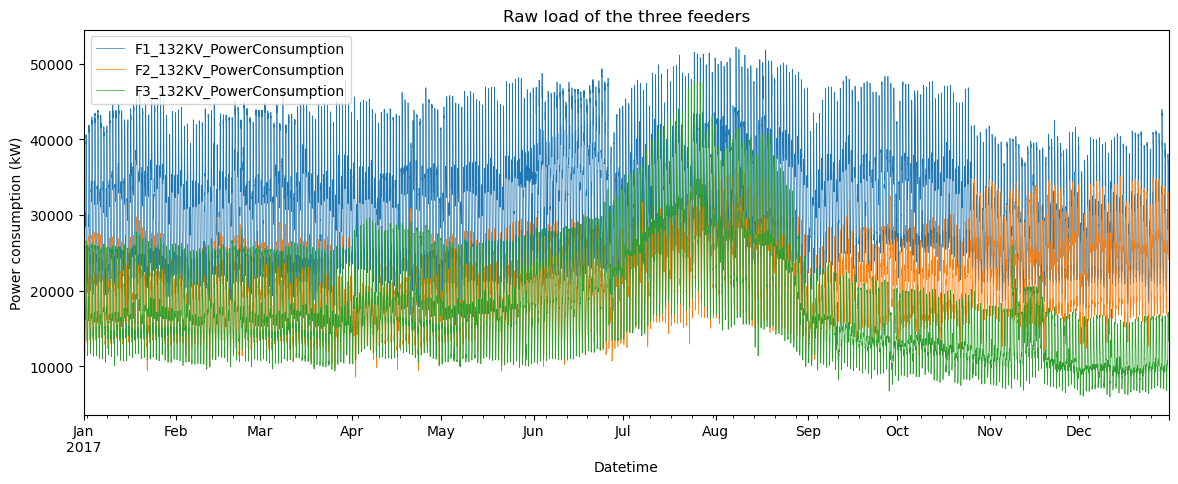

In [7]:
df = df.set_index("Datetime")

feeders = ["F1_132KV_PowerConsumption", "F2_132KV_PowerConsumption", "F3_132KV_PowerConsumption"]

print(df[feeders].describe().round(0))

df[feeders].plot(figsize=(14, 5), linewidth=0.5, title="Raw load of the three feeders")
plt.ylabel("Power consumption (kW)")
plt.show()

## 6. Outlier Detection
We use the IQR method with a wide fence (3 x IQR) to flag only extreme values.

In [8]:
for f in feeders:
    q1 = df[f].quantile(0.25)
    q3 = df[f].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 3 * iqr
    lower = q1 - 3 * iqr
    outliers = df[(df[f] > upper) | (df[f] < lower)]
    print(f, "| upper fence:", round(upper), "| outliers:", len(outliers))

F1_132KV_PowerConsumption | upper fence: 70304 | outliers: 0
F2_132KV_PowerConsumption | upper fence: 47913 | outliers: 0
F3_132KV_PowerConsumption | upper fence: 47108 | outliers: 18


## 7. Investigating the F3 Outliers
Before removing anything, we check when the 18 F3 outliers occur.

In [9]:
f3 = df["F3_132KV_PowerConsumption"]

q1 = f3.quantile(0.25)
q3 = f3.quantile(0.75)
upper = q3 + 3 * (q3 - q1)

f3_out = f3[f3 > upper]
print(f3_out.round(0))

Datetime
2017-07-23 20:00:00    47267.0
2017-07-23 20:10:00    47279.0
2017-07-23 20:20:00    47146.0
2017-07-24 20:00:00    47430.0
2017-07-24 20:10:00    47598.0
2017-07-24 20:20:00    47406.0
2017-07-24 20:30:00    47219.0
2017-07-25 20:10:00    47171.0
2017-07-25 20:20:00    47255.0
2017-07-26 19:50:00    47291.0
2017-07-26 20:00:00    47580.0
2017-07-26 20:10:00    47508.0
2017-07-26 20:20:00    47442.0
2017-07-27 19:50:00    47177.0
2017-07-27 20:00:00    47152.0
2017-07-27 20:10:00    47598.0
2017-07-27 20:20:00    47436.0
2017-07-27 20:30:00    47219.0
Name: F3_132KV_PowerConsumption, dtype: float64


**Decision:** The 18 F3 outliers all occur between 19:50 and 20:30 on 23-27 July, at nearly the same level (~47,200-47,600). A sensor error would not repeat daily at the same time and magnitude, so these are a genuine summer evening peak. We keep them, because the model must learn these peaks.

In [10]:
print("Zero or negative readings:")
print((df[feeders] <= 0).sum())

Zero or negative readings:
F1_132KV_PowerConsumption    0
F2_132KV_PowerConsumption    0
F3_132KV_PowerConsumption    0
dtype: int64


## 8. Sudden Jumps Between Consecutive Readings
A real load changes smoothly over 10 minutes. Very large jumps between two consecutive readings can indicate sensor glitches, so we list the biggest ones.

In [11]:
jumps = df[feeders].pct_change().abs()

for f in feeders:
    print(f)
    print(jumps[f].nlargest(5).round(3))
    print()

F1_132KV_PowerConsumption
Datetime
2017-04-20 12:10:00    0.535
2017-04-20 12:30:00    0.517
2017-08-30 02:00:00    0.364
2017-01-14 23:10:00    0.267
2017-01-15 12:30:00    0.222
Name: F1_132KV_PowerConsumption, dtype: float64

F2_132KV_PowerConsumption
Datetime
2017-12-11 11:00:00    0.300
2017-12-11 11:10:00    0.249
2017-01-15 12:30:00    0.206
2017-01-01 00:10:00    0.201
2017-01-22 17:30:00    0.183
Name: F2_132KV_PowerConsumption, dtype: float64

F3_132KV_PowerConsumption
Datetime
2017-09-28 05:50:00    0.721
2017-09-28 05:30:00    0.365
2017-12-11 07:00:00    0.359
2017-12-11 07:10:00    0.294
2017-11-10 07:50:00    0.283
Name: F3_132KV_PowerConsumption, dtype: float64



## 9. Looking Closely at the Biggest Jump (F1, 20 April)
We plot the hours around the biggest jump to decide whether it is a single-point glitch or a sustained change.

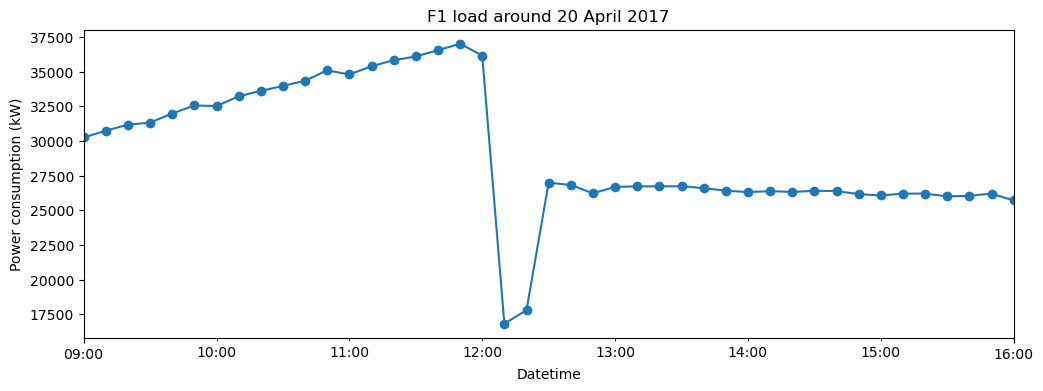

In [12]:
window = df.loc["2017-04-20 09:00":"2017-04-20 16:00", "F1_132KV_PowerConsumption"]

window.plot(figsize=(12, 4), marker="o", title="F1 load around 20 April 2017")
plt.ylabel("Power consumption (kW)")
plt.show()

**Decision:** The largest jump (F1, 20 April 12:10) is not a single-point glitch. The load drops from ~36,000 to ~17,000 for 20 minutes and then settles at a new level of ~26,000, so it behaves like a real operational event (e.g. load transfer or switching). Replacing it by interpolation would invent data. We keep these points, and later use a tree-based model and robust error metrics (MAE) that are not distorted by a few such events.

## 10. Converting to 30-Minute Blocks
The forecast is required for each 30-minute block (48 per day), so we average every three 10-minute readings. Power consumption is a rate (kW), so the mean of the three readings is the average demand for that block. We also create Total_Load as the sum of the three feeders.

In [13]:
df30 = df[feeders].resample("30min").mean()
df30["Total_Load"] = df30[feeders].sum(axis=1)

print("Shape:", df30.shape)
print("Blocks per day:", df30.groupby(df30.index.date).size().unique())
print("Missing values:", df30.isnull().sum().sum())
df30.to_csv("data/load_clean_30min.csv")
df30.head()

Shape: (17472, 4)
Blocks per day: [48]
Missing values: 0


,F1_132KV_PowerConsumption,F2_132KV_PowerConsumption,F3_132KV_PowerConsumption,Total_Load
Datetime,,,,
2017-01-01 00:00:00,30999.493670,18170.212767,20013.493977,69183.200413
2017-01-01 00:30:00,27396.455697,17883.282673,18490.602410,63770.340780
2017-01-01 01:00:00,25407.594937,16627.355623,17476.626507,59511.577067
2017-01-01 01:30:00,23906.835443,15529.483283,16609.156627,56045.475353
2017-01-01 02:00:00,22474.936707,14767.173253,15870.843373,53112.953333


## 11. Time-Based Patterns
We add the hour of day and a weekend flag to study daily and weekly patterns.

In [14]:
df30["hour"] = df30.index.hour + df30.index.minute / 60
df30["weekend"] = df30.index.dayofweek >= 5   # 5 = Saturday, 6 = Sunday
df30[["Total_Load", "hour", "weekend"]].head()

,Total_Load,hour,weekend
Datetime,,,
2017-01-01 00:00:00,69183.200413,0.0,True
2017-01-01 00:30:00,63770.340780,0.5,True
2017-01-01 01:00:00,59511.577067,1.0,True
2017-01-01 01:30:00,56045.475353,1.5,True
2017-01-01 02:00:00,53112.953333,2.0,True


### Daily pattern
Average Total_Load for each half-hour of the day, weekdays vs weekends.

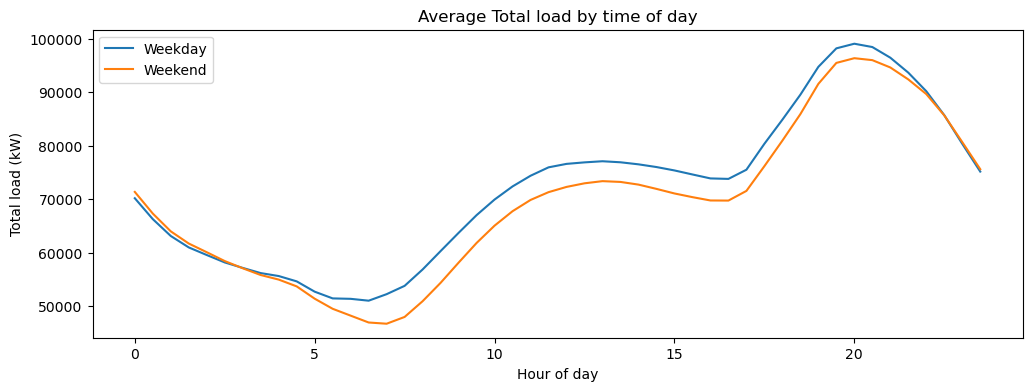

Peak at 20.0 h: 98310
Lowest at 6.5 h: 49883


In [15]:
daily = df30.groupby(["weekend", "hour"])["Total_Load"].mean().unstack(0)
daily.columns = ["Weekday", "Weekend"]

daily.plot(figsize=(12, 4), title="Average Total load by time of day")
plt.xlabel("Hour of day")
plt.ylabel("Total load (kW)")
plt.show()

avg = df30.groupby("hour")["Total_Load"].mean()
print("Peak at", avg.idxmax(), "h:", round(avg.max()))
print("Lowest at", avg.idxmin(), "h:", round(avg.min()))

**Observation:** Load is lowest around 06:30 (~50k kW), rises through the day and reaches a sharp evening peak at 20:00 (~98k kW). Weekends are lower than weekdays on average.

### Weekly pattern
Average Total_Load by day of the week.

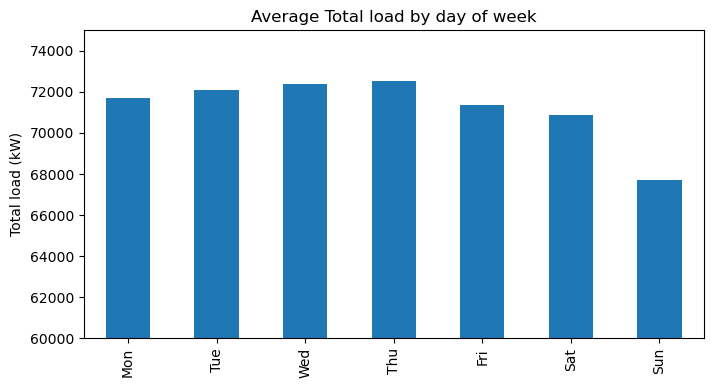

Weekend vs weekday: -3.8%


In [16]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekly = df30.groupby(df30.index.dayofweek)["Total_Load"].mean()
weekly.index = days

weekly.plot(kind="bar", figsize=(8, 4), title="Average Total load by day of week")
plt.ylabel("Total load (kW)")
plt.ylim(60000, 75000)
plt.show()

w = df30.groupby("weekend")["Total_Load"].mean()
print(f"Weekend vs weekday: {w[True] / w[False] - 1:+.1%}")

**Observation:** Thursday is the highest day (~72.5k kW) and Sunday the lowest (~67.7k kW). The weekend is ~3.8% lower than weekdays. The y-axis starts at 60,000, so the differences look larger than they really are; the weekly effect is modest compared with the daily and seasonal effects.

### Monthly (seasonal) pattern
Average Total_Load for each month of 2017.

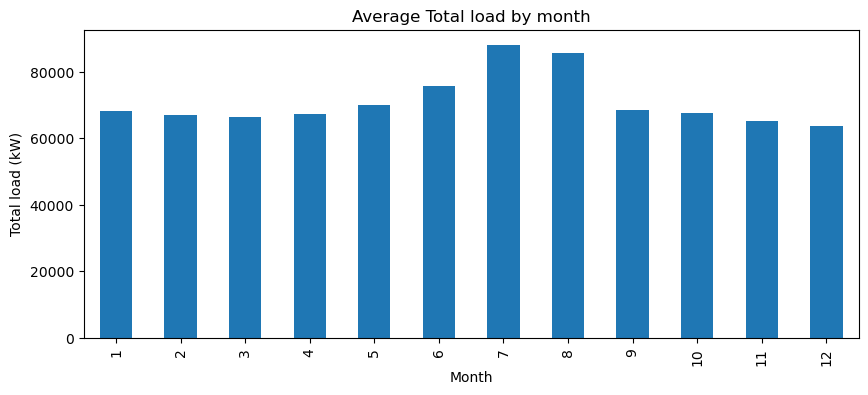

Datetime
1     68173.0
2     67109.0
3     66561.0
4     67397.0
5     69994.0
6     75707.0
7     88174.0
8     85740.0
9     68500.0
10    67561.0
11    65105.0
12    63751.0
Name: Total_Load, dtype: float64


In [17]:
monthly = df30.groupby(df30.index.month)["Total_Load"].mean()

monthly.plot(kind="bar", figsize=(10, 4), title="Average Total load by month")
plt.xlabel("Month")
plt.ylabel("Total load (kW)")
plt.show()
print(monthly.round(0))

**Observation:** Load is strongly seasonal. July (~88k kW) and August (~86k kW) are the highest months, June is already elevated (~76k kW), and December is the lowest (~64k kW). The remaining months stay between ~65k and ~70k kW.

### Hour of day vs month
A heatmap shows how the daily shape changes with the season.

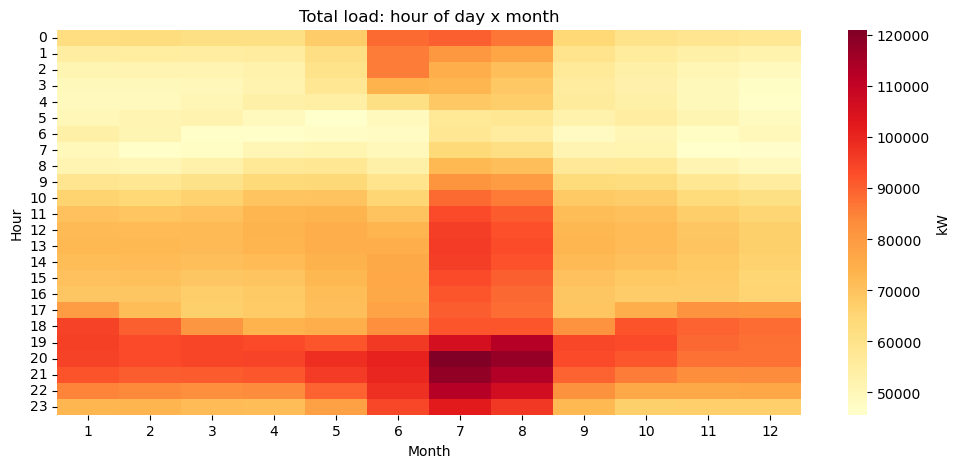

In [18]:
pivot = df30.pivot_table(index=df30.index.hour, columns=df30.index.month,
                         values="Total_Load", aggfunc="mean")

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "kW"})
plt.title("Total load: hour of day x month")
plt.xlabel("Month")
plt.ylabel("Hour")
plt.show()

**Observation:** Every month has its peak in the evening hours, but the July-August evening peak is clearly the strongest. This means the effect of the time of day depends on the season, which a model should be able to capture (e.g. through month and temperature features together with the hour).

### Feeder comparison
Share of total load per feeder and the correlation between feeders.

Share of total load (%):
F1_132KV_PowerConsumption    45.4
F2_132KV_PowerConsumption    29.5
F3_132KV_PowerConsumption    25.0
dtype: float64


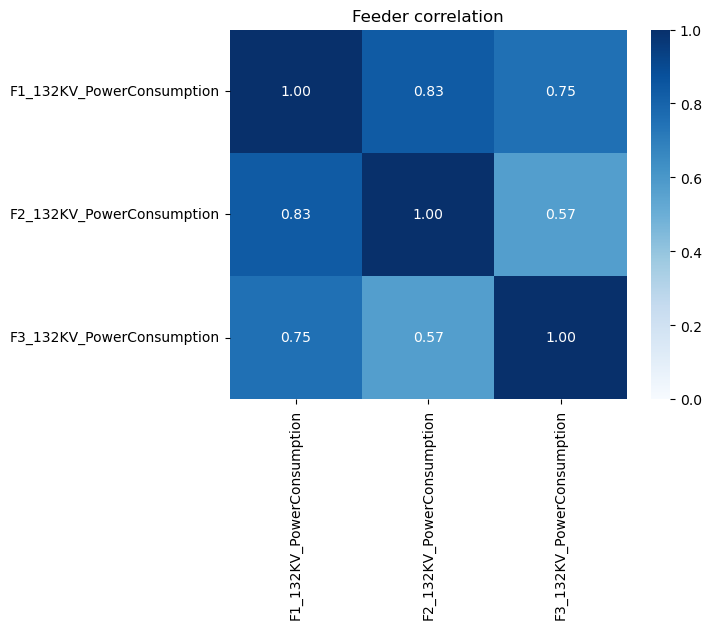

In [19]:
share = (df30[feeders].mean() / df30[feeders].mean().sum() * 100).round(1)
print("Share of total load (%):")
print(share)

corr = df30[feeders].corr()
sns.heatmap(corr, annot=True, cmap="Blues", vmin=0, vmax=1, fmt=".2f")
plt.title("Feeder correlation")
plt.show()

### Autocorrelation
How strongly is the load related to its own past? This tells us which lag features will be useful.

In [20]:
s = df30["Total_Load"]
lags = {"1 hour": 2, "6 hours": 12, "24 hours": 48, "7 days": 336}

for name, n in lags.items():
    print(f"{name:>8}: {s.autocorr(n):.2f}")

  1 hour: 0.93
 6 hours: 0.11
24 hours: 0.98
  7 days: 0.97


The 6-hour autocorrelation is low because the daily cycle puts the load at the opposite phase 6 hours earlier. The 24-hour and 7-day values are very high, so lag features at 48 and 336 blocks will be strong predictors.

## 12. Summary of Findings and Modelling Decisions

| Finding | Modelling decision |
|---|---|
| Date column mixes two month-first formats | Explicit parsing of each format (no day-first guessing) |
| No missing timestamps, no duplicates, no zero/negative readings | No gap filling needed; same checks kept for future data |
| 18 F3 "outliers" are a repeating July evening peak | Kept; the model must learn real peaks |
| F1 shows a sustained level shift on 20 April | Kept; use a tree-based model and MAE, which are robust to rare events |
| Strong daily cycle: peak at 20:00 (~98k kW), low at 06:30 (~50k kW) | Hour/half-hour-of-day features |
| Weekend load is ~3.8% lower than weekdays | Day-of-week and weekend features, plus holiday flags |
| Strong seasonality: July-August peak (~88k kW) vs December (~64k kW) | Month and day-of-year features, plus temperature |
| Autocorrelation is 0.98 at 24 h and 0.97 at 7 days | Lag features at 24 h and 7 days |
| Feeders differ in size and behaviour (F1 45%, F2 30%, F3 25%) | Forecast Total_Load and each feeder |